**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Joshua Gamboa Calvo
*   MATRÍCULA: A01841021

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [37]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [38]:
cardio_df = pd.read_csv('heart_disease.csv',index_col='id')
cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [39]:
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


### ¿Cuántas columnas son numéricas y cuántas de texto?

Hay 7 columnas numericas y 7 de texto (sin contar `id`)

In [40]:
cardio_df.select_dtypes(include=np.number).nunique()

,0
age,50
trestbps,60
chol,216
thalch,119
oldpeak,53
ca,4
num,5


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [41]:
print("Unique values for 'ca':", cardio_df['ca'].unique())
print("Unique values for 'num':", cardio_df['num'].unique())

Unique values for 'ca': [ 0.  3.  2.  1. nan]
Unique values for 'num': [0 2 1 3 4]


In [42]:
# Definir las categorías ordinales para 'ca' y 'num'
ca_categories = pd.CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
num_categories = pd.CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

# Convertir las columnas en el DataFrame
cardio_df['ca'] = cardio_df['ca'].astype(ca_categories)
cardio_df['num'] = cardio_df['num'].astype(num_categories)

# Verificar los cambios
cardio_df[['ca', 'num']].dtypes

,0
ca,category
num,category


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [43]:
num_cols = cardio_df.select_dtypes(include=np.number)

num_desc = num_cols.describe().T
num_desc['skew'] = num_cols.skew()
num_desc['kurtosis'] = num_cols.kurtosis()
num_desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [44]:
cat_cols = cardio_df.select_dtypes(exclude=np.number)
cat_cols.describe(include='all').T

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411


In [45]:
for col in cat_cols.columns:
    freq_df = pd.DataFrame({
        f'Frecuencia Absoluta de {col}': cardio_df[col].value_counts(dropna=False),
        f'Porcentaje (%) de {col}': cardio_df[col].value_counts(dropna=False, normalize=True) * 100
    })
    display(freq_df)

,Frecuencia Absoluta de sex,Porcentaje (%) de sex
sex,,
Male,724,78.867102
Female,194,21.132898


,Frecuencia Absoluta de origin,Porcentaje (%) de origin
origin,,
Cleveland,304,33.115468
Hungary,292,31.808279
VA Long Beach,200,21.786492
Switzerland,122,13.289760


,Frecuencia Absoluta de cp,Porcentaje (%) de cp
cp,,
asymptomatic,495,53.921569
non-anginal,204,22.222222
atypical angina,174,18.954248
typical angina,45,4.901961


,Frecuencia Absoluta de fbs,Porcentaje (%) de fbs
fbs,,
False,691,75.272331
True,138,15.032680
NaN,89,9.694989


,Frecuencia Absoluta de restecg,Porcentaje (%) de restecg
restecg,,
normal,551,60.021786
lv hypertrophy,188,20.479303
st-t abnormality,179,19.498911


,Frecuencia Absoluta de exang,Porcentaje (%) de exang
exang,,
False,526,57.298475
True,337,36.710240
NaN,55,5.991285


,Frecuencia Absoluta de slope,Porcentaje (%) de slope
slope,,
flat,345,37.581699
NaN,308,33.551198
upsloping,202,22.004357
downsloping,63,6.862745


,Frecuencia Absoluta de ca,Porcentaje (%) de ca
ca,,
NaN,609,66.339869
0.0,181,19.716776
1.0,67,7.298475
2.0,41,4.466231
3.0,20,2.178649


,Frecuencia Absoluta de thal,Porcentaje (%) de thal
thal,,
NaN,484,52.723312
normal,196,21.350763
reversable defect,192,20.915033
fixed defect,46,5.010893


,Frecuencia Absoluta de num,Porcentaje (%) de num
num,,
0,411,44.771242
1,263,28.649237
2,109,11.873638
3,107,11.655773
4,28,3.050109


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [46]:
null_count = cardio_df.isnull().sum()
null_count

,0
age,0
sex,0
origin,0
cp,0
trestbps,59
chol,30
fbs,89
restecg,0
thalch,55
exang,55


In [47]:
missing_percentage = (null_count / len(cardio_df)) * 100
missing_percentage

,0
age,0.000000
sex,0.000000
origin,0.000000
cp,0.000000
trestbps,6.427015
chol,3.267974
fbs,9.694989
restecg,0.000000
thalch,5.991285
exang,5.991285


In [48]:
for col in missing_percentage.index:
    if missing_percentage[col] > 30:
        cardio_df.drop(columns=col, inplace=True)

cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
id,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0


## Decision


Dado a que las columnas `slope`, `ca` y `thal` tienen un porcentaje de valores nulos mayor al 30%, fueron descartados del análisis debido a que no proveen de una muestra estadisticamente relevante.

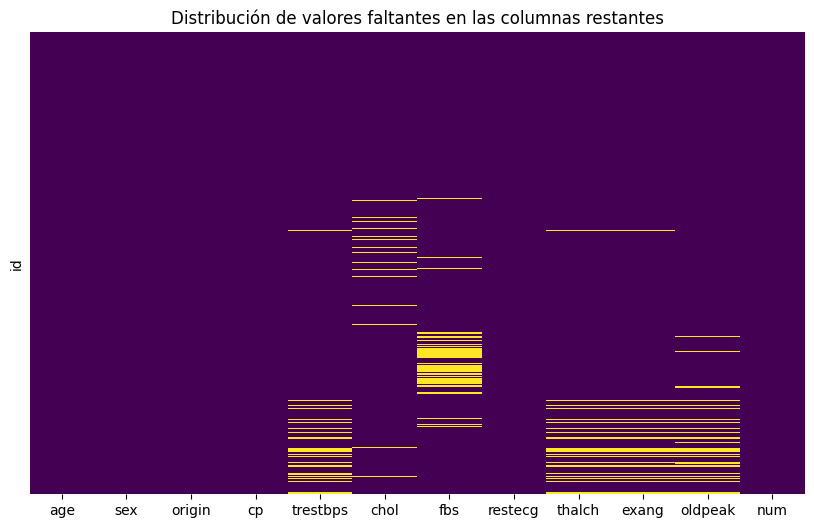

In [52]:
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Distribución de valores faltantes en las columnas restantes')
plt.show()

In [54]:
columns_to_check = ['trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak']

mask_two_or_more_null = cardio_df[columns_to_check].isnull().sum(axis=1) >= 2
matching_rows = cardio_df[mask_two_or_more_null]

print(f"Cantidad de filas encontradas: {len(matching_rows)}")
matching_rows

Cantidad de filas encontradas: 59


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
id,,,,,,,,,,,,
394,48,Female,Hungary,atypical angina,NaN,308.0,False,st-t abnormality,NaN,NaN,2.0,0
600,35,Male,Switzerland,asymptomatic,NaN,223.0,NaN,normal,130.0,True,NaN,3
607,38,Male,Switzerland,asymptomatic,150.0,223.0,NaN,normal,120.0,True,NaN,1
637,52,Male,Switzerland,asymptomatic,95.0,223.0,NaN,normal,82.0,True,NaN,2
706,65,Male,Switzerland,asymptomatic,145.0,223.0,NaN,st-t abnormality,67.0,False,NaN,3
715,69,Male,Switzerland,asymptomatic,NaN,223.0,False,st-t abnormality,NaN,NaN,NaN,3
734,63,Male,VA Long Beach,non-anginal,NaN,223.0,False,lv hypertrophy,NaN,NaN,NaN,1
744,74,Male,VA Long Beach,non-anginal,NaN,223.0,False,normal,NaN,NaN,NaN,0
747,51,Male,VA Long Beach,asymptomatic,NaN,223.0,True,st-t abnormality,NaN,NaN,NaN,2


### Análisis

Mi hipótesis inicial era que los valores nulos corresponden simplemente a pacientes a quienes no se les realizó la prueba, por lo que todas las variables relacionadas con ella (trestbps, thalch, exang y oldpeak) no se registraron. Al revisar la muestra de unas 57 filas con nulos, encuentro que la hipótesis se sostiene en buena parte, con un matiz importante: la ausencia no depende del paciente sino del hospital. Solo una fila es de Hungría y cinco son de Suiza; el resto es de VA Long Beach y ninguna es de Cleveland. En VA Long Beach, trestbps, thalch, exang y oldpeak faltan juntas en casi todas las filas, mientras que chol, fbs y restecg están en su mayoría presentes, lo que coincide con que la prueba de esfuerzo no se hizo o no se registró en ese sitio. En Suiza el patrón es menos limpio: varias filas tienen thalch y exang registradas pero oldpeak faltante, así que ahí parece haber diferencias de registro por campo y no una prueba que nunca se realizó. Por eso concluyo que los nulos se explican sobre todo por el sitio y su protocolo (MAR condicionado a origin), y que no parecen asociados a un solo grado de enfermedad, ya que num abarca de 0 a 4.

Además, encontré un problema de calidad de datos que isnull() no detecta: el valor chol = 223 aparece en cerca de una cuarta parte de estas filas, casi todas de Suiza y VA Long Beach. Es demasiado frecuente para ser real y parece un valor de relleno o una imputación previa en el origen, así que la columna chol mezcla valores reales, NaN verdaderos y 223 falsos.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [49]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [50]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---